# Análisis Predictivo Empresarial

**Autores:** Jonathan Ortiz Calderon y Carolina Suarez Castro  
**Repositorio:** [TALLER-PRACTICA-ANALISIS-PREDICTIVO](https://github.com/jonathanortizcalderon-droid/TALLER-PRACTICA-ANALISIS-PREDICTIVO)

## Contexto y fundamentos

Esta práctica aplica el capítulo de análisis predictivo de la Guía Analítica Empresarial y el artículo [What is Predictive Analytics?](https://cloud.google.com/learn/what-is-predictive-analytics?hl=es). El análisis predictivo combina datos históricos, estadística y aprendizaje automático para estimar resultados futuros y apoyar decisiones; no sustituye el juicio del negocio.

**Descriptivo** responde qué ocurrió (por ejemplo, ingresos mensuales históricos). **Predictivo** estima qué podría ocurrir (por ejemplo, ingresos de los próximos meses). Los elementos del modelo son: datos y objetivo, limpieza, variables relevantes, algoritmo, validación e interpretación para la decisión.

El objetivo empresarial es proyectar el ingreso neto mensual a partir de `clientes.json`, `productos.xlsx` y `ventas.csv`. El resultado puede orientar inventario, presupuesto, campañas y capacidad operativa.

## Criterios de entrega

| Criterio | Evidencia dentro del notebook |
|---|---|
| Comprensión del análisis predictivo empresarial | Contexto, objetivo de negocio y fundamentos de esta sección. |
| Diferencia descriptivo/predictivo | Comparación conceptual y análisis histórico antes de la proyección. |
| Elementos de un modelo predictivo | Datos, limpieza, variables, algoritmo, validación e interpretación. |
| Carga y exploración | Sección 1: carga de las tres fuentes, dimensiones, faltantes y duplicados. |
| Preparación y limpieza | Sección 2: fechas, categorías, descuentos, devoluciones e integración. |
| Selección de variables | Sección 4: tendencia, rezago y media móvil. |
| Modelo predictivo básico | Sección 5: regresión lineal y baseline. |
| Visualizaciones de resultados | Secciones 3 y 5-6: histórico, canales, evaluación y proyección. |
| Interpretación y toma de decisiones | Sección 6 y conclusiones finales. |
| Referencias | Sección final de referencias consultadas. |

In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
BASE = Path.cwd()
required_files = ['clientes.json', 'productos.xlsx', 'ventas.csv']
missing = [name for name in required_files if not (BASE / name).exists()]
if missing:
    raise FileNotFoundError(f'No se encontraron: {missing}. Ejecute el notebook desde la carpeta de datos.')
print('Carpeta:', BASE.resolve())

Carpeta: C:\Users\Jonathan Ortiz\Desktop\IA\Especializacion II\Business_Analytics\Trabajo_4


## 1. Carga y exploración de datos

Se revisan dimensiones, tipos, faltantes y duplicados antes de transformar los datos.

In [2]:
with open(BASE / 'clientes.json', encoding='utf-8') as file:
    clientes = pd.DataFrame(json.load(file))
productos = pd.read_excel(BASE / 'productos.xlsx')
ventas = pd.read_csv(BASE / 'ventas.csv', sep=';')
for name, frame in [('clientes', clientes), ('productos', productos), ('ventas', ventas)]:
    print(f'\n{name}: {frame.shape[0]} filas x {frame.shape[1]} columnas')
    display(frame.head())
    print('Faltantes:', frame.isna().sum().to_dict(), '| Duplicados:', int(frame.duplicated().sum()))


clientes: 15 filas x 5 columnas


,id_cliente,nombre,email,ciudad,fecha_registro
0,1,Ana Gómez,ana1@correo.com,bogota,2024-01-24
1,2,Luis Pérez,luis2@correo.com,Cali,2024-04-08
2,3,María Rodríguez,maría3@correo.com,Medellín,2024-12-04
3,4,Carlos López,NaN,Bogotá,2024-02-19
4,5,LAURA MARTÍNEZ,laura5@correo.com,Bucaramanga,2024-01-01


Faltantes: {'id_cliente': 0, 'nombre': 0, 'email': 2, 'ciudad': 0, 'fecha_registro': 0} | Duplicados: 0

productos: 10 filas x 4 columnas


,id_producto,nombre,categoria,precio_unitario
0,P001,Portátil,Computo,3200000
1,P002,Mouse,Accesorios,45000
2,P003,Teclado,accesorios,120000
3,P004,"Monitor 24""",Computo,780000
4,P005,Audífonos,Audio,150000


Faltantes: {'id_producto': 0, 'nombre': 0, 'categoria': 0, 'precio_unitario': 0} | Duplicados: 0

ventas: 515 filas x 7 columnas


,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal
0,490,2025-05-20,7,P003,2.0,15%,Web
1,430,2025/03/27,1,P004,1.0,10%,Web
2,83,2025-12-06,14,P003,1.0,NaN,web
3,121,2025/12/19,13,P005,3.0,15%,App
4,222,2025/07/29,2,P006,-3.0,0%,Tienda


Faltantes: {'id_venta': 0, 'fecha': 0, 'id_cliente': 0, 'id_producto': 0, 'cantidad': 9, 'descuento': 135, 'canal': 0} | Duplicados: 15


## 2. Preparación, limpieza e integración

Se normalizan espacios y mayúsculas, se convierten las fechas con los tres formatos presentes en la fuente, y se transforman los descuentos porcentuales a proporciones. Las cantidades negativas se conservan como devoluciones porque afectan el ingreso neto y constituyen información empresarial. La unión se valida para detectar claves sin correspondencia.

In [3]:
def parse_date(value):
    if pd.isna(value):
        return pd.NaT
    for fmt in ('%Y-%m-%d', '%Y/%m/%d', '%d/%m/%Y'):
        result = pd.to_datetime(str(value).strip(), format=fmt, errors='coerce')
        if not pd.isna(result):
            return result
    return pd.NaT

def parse_discount(value):
    if pd.isna(value) or str(value).strip() == '':
        return 0.0
    return pd.to_numeric(str(value).strip().replace('%', '').replace(',', '.'), errors='coerce') / 100

def clean_text(series):
    return series.astype('string').str.strip().str.lower()

clientes = clientes.copy()
productos = productos.copy()
ventas = ventas.copy()
clientes['ciudad'] = clean_text(clientes['ciudad'])
clientes['fecha_registro'] = clientes['fecha_registro'].map(parse_date)
ventas['fecha'] = ventas['fecha'].map(parse_date)
ventas['canal'] = clean_text(ventas['canal'])
ventas['id_producto'] = ventas['id_producto'].astype('string').str.strip().str.upper()
ventas['id_cliente'] = pd.to_numeric(ventas['id_cliente'], errors='coerce').astype('Int64')
ventas['cantidad'] = pd.to_numeric(ventas['cantidad'], errors='coerce')
ventas['descuento_proporcion'] = ventas['descuento'].map(parse_discount).fillna(0)

productos.columns = [re.sub(r'[^a-z0-9_]', '', str(column).strip().lower().replace(' ', '_')) for column in productos.columns]
aliases = {'id': 'id_producto', 'codigo': 'id_producto', 'producto_id': 'id_producto', 'valor': 'precio', 'precio_unitario': 'precio'}
productos = productos.rename(columns={column: aliases.get(column, column) for column in productos.columns})
needed = {'id_producto', 'precio'}
if not needed.issubset(productos.columns):
    raise KeyError(f'productos.xlsx debe tener {sorted(needed)}; encontró {list(productos.columns)}')
productos['id_producto'] = productos['id_producto'].astype('string').str.strip().str.upper()
productos['precio'] = pd.to_numeric(productos['precio'], errors='coerce')
print('Fechas no interpretadas:', int(ventas['fecha'].isna().sum()))
print('Devoluciones:', int((ventas['cantidad'] < 0).sum()))
print('Canales:', sorted(ventas['canal'].dropna().unique().tolist()))

Fechas no interpretadas: 0
Devoluciones: 13
Canales: ['app', 'tienda', 'web']


In [4]:
ventas_modelo = ventas.merge(productos[['id_producto', 'precio']], on='id_producto', how='left', validate='many_to_one', indicator='producto_ok')
ventas_modelo = ventas_modelo.merge(clientes[['id_cliente', 'ciudad']], on='id_cliente', how='left', validate='many_to_one', indicator='cliente_ok')
print('Ventas sin producto:', int((ventas_modelo['producto_ok'] == 'left_only').sum()))
print('Ventas sin cliente:', int((ventas_modelo['cliente_ok'] == 'left_only').sum()))
ventas_modelo['ingreso_neto'] = ventas_modelo['cantidad'] * ventas_modelo['precio'] * (1 - ventas_modelo['descuento_proporcion'])
ventas_modelo = ventas_modelo.drop(columns=['producto_ok', 'cliente_ok']).dropna(subset=['fecha', 'cantidad', 'precio', 'ingreso_neto'])
ventas_modelo['mes'] = ventas_modelo['fecha'].dt.to_period('M').dt.to_timestamp()
display(ventas_modelo.head())
print('Registros utilizables:', len(ventas_modelo))

Ventas sin producto: 0
Ventas sin cliente: 26


,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal,descuento_proporcion,precio,ciudad,ingreso_neto,mes
0,490,2025-05-20,7,P003,2.0,15%,web,0.15,120000,bogotá,204000.0,2025-05-01
1,430,2025-03-27,1,P004,1.0,10%,web,0.10,780000,bogota,702000.0,2025-03-01
2,83,2025-12-06,14,P003,1.0,NaN,web,0.00,120000,barranquilla,120000.0,2025-12-01
3,121,2025-12-19,13,P005,3.0,15%,app,0.15,150000,medellín,382500.0,2025-12-01
4,222,2025-07-29,2,P006,-3.0,0%,tienda,0.00,650000,cali,-1950000.0,2025-07-01


Registros utilizables: 506


## 3. Análisis descriptivo y generación de visualizaciones

Esta etapa responde qué ocurrió antes de estimar el futuro. El ingreso neto mensual es la variable objetivo porque refleja ventas, precios, descuentos y devoluciones en una sola medida. Las dos visualizaciones siguientes hacen visible el comportamiento histórico y el aporte acumulado de cada canal; son resultados descriptivos que sirven como base para el análisis predictivo.

,mes,ingreso_neto,unidades,transacciones
0,2025-01-01,41392500.0,115.0,35
1,2025-02-01,127127000.0,181.0,55
2,2025-03-01,60930500.0,119.0,41
3,2025-04-01,62063250.0,117.0,46
4,2025-05-01,33903250.0,93.0,37
5,2025-06-01,59045000.0,115.0,38
6,2025-07-01,144293500.0,155.0,44
7,2025-08-01,64985250.0,129.0,41
8,2025-09-01,94975250.0,133.0,44
9,2025-10-01,53249500.0,102.0,41


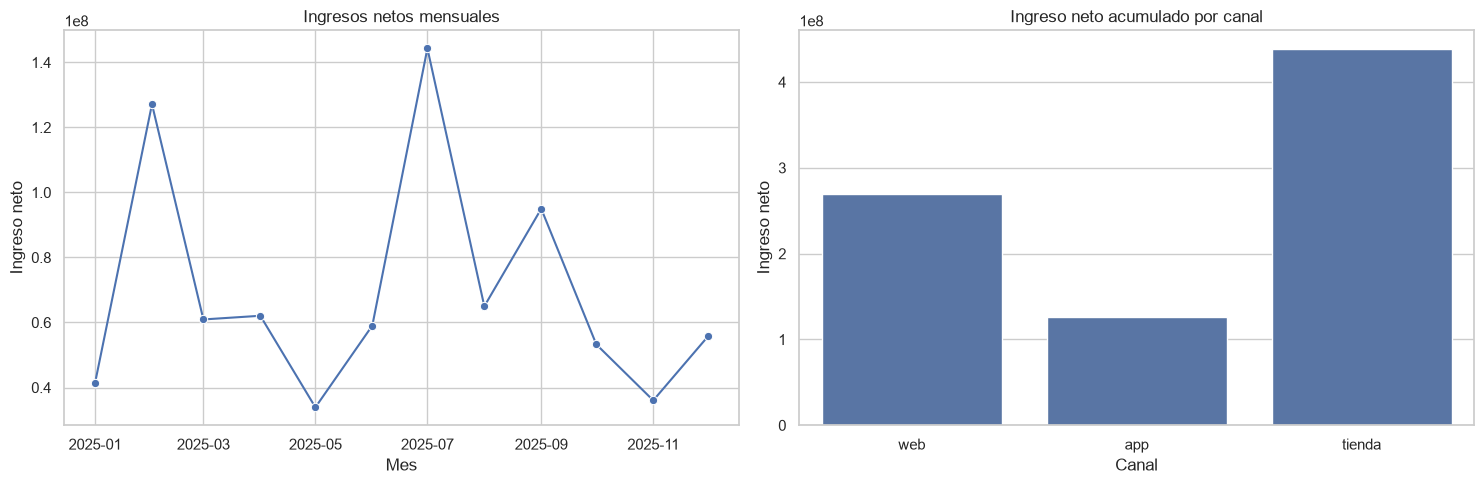

In [5]:
monthly = (ventas_modelo.groupby('mes', as_index=False)
           .agg(ingreso_neto=('ingreso_neto', 'sum'), unidades=('cantidad', 'sum'), transacciones=('id_venta', 'nunique'))
           .sort_values('mes'))
display(monthly)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(data=monthly, x='mes', y='ingreso_neto', marker='o', ax=axes[0])
axes[0].set(title='Ingresos netos mensuales', xlabel='Mes', ylabel='Ingreso neto')
sns.barplot(data=ventas_modelo, x='canal', y='ingreso_neto', estimator='sum', errorbar=None, ax=axes[1])
axes[1].set(title='Ingreso neto acumulado por canal', xlabel='Canal', ylabel='Ingreso neto')
plt.tight_layout(); plt.show()

## 4. Variables relevantes y validación temporal

Se usan tendencia temporal, ingreso del mes anterior y promedio móvil de tres meses. Son variables interpretables y disponibles para proyectar. La separación respeta el orden temporal: los primeros meses entrenan y los últimos meses evalúan. Así se evita usar información futura en el entrenamiento.

In [6]:
series = monthly[['mes', 'ingreso_neto']].copy().reset_index(drop=True)
series['tendencia'] = np.arange(len(series))
series['ingreso_lag_1'] = series['ingreso_neto'].shift(1)
series['media_movil_3'] = series['ingreso_neto'].shift(1).rolling(3).mean()
model_data = series.dropna().reset_index(drop=True)
if len(model_data) < 6:
    raise ValueError('Se requieren al menos seis meses para entrenar y evaluar el modelo.')
features = ['tendencia', 'ingreso_lag_1', 'media_movil_3']
test_size = min(max(3, int(np.ceil(len(model_data) * 0.2))), len(model_data) - 3)
train = model_data.iloc[:-test_size].copy()
test = model_data.iloc[-test_size:].copy()
print(f'Entrenamiento: {len(train)} meses | Prueba: {len(test)} meses')
display(model_data[['mes'] + features + ['ingreso_neto']].tail())

Entrenamiento: 6 meses | Prueba: 3 meses


,mes,tendencia,ingreso_lag_1,media_movil_3,ingreso_neto
4,2025-08-01,7,144293500.0,7.908058e+07,64985250.0
5,2025-09-01,8,64985250.0,8.944125e+07,94975250.0
6,2025-10-01,9,94975250.0,1.014180e+08,53249500.0
7,2025-11-01,10,53249500.0,7.107000e+07,36027500.0
8,2025-12-01,11,36027500.0,6.141742e+07,55850500.0


## 5. Modelo predictivo básico y evaluación

La regresión lineal estima el ingreso como combinación de las variables anteriores. Se compara con un baseline que usa directamente el ingreso del mes anterior. MAE y RMSE se expresan en unidades monetarias; R² resume la variabilidad explicada en la muestra de prueba. En esta práctica, la evaluación es orientativa porque la serie es corta.

,MAE,RMSE,R2
Regresión lineal,2.524767e+07,2.858440e+07,-9.560772
Baseline (mes anterior),2.625692e+07,2.846394e+07,-9.471946


,coeficiente
tendencia,2.226837e-09
ingreso_lag_1,1.155629e-01
media_movil_3,-1.138748e+00


Intercepto: 150410252.6230545


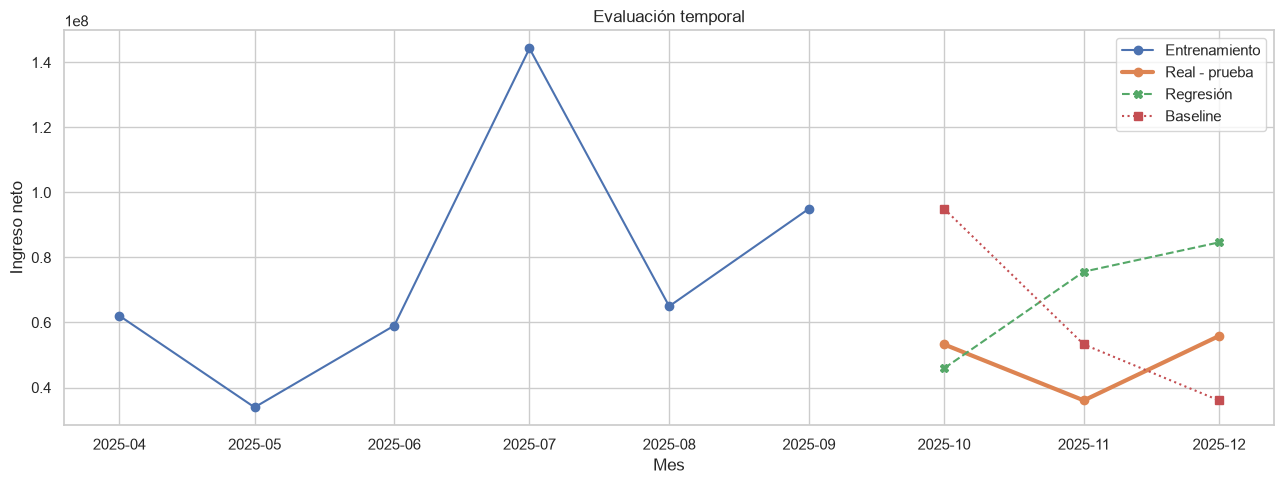

In [7]:
regression = LinearRegression().fit(train[features], train['ingreso_neto'])
test['prediccion_regresion'] = regression.predict(test[features])
test['prediccion_baseline'] = test['ingreso_lag_1']
def metrics(actual, predicted):
    return {'MAE': mean_absolute_error(actual, predicted), 'RMSE': np.sqrt(mean_squared_error(actual, predicted)), 'R2': r2_score(actual, predicted)}
scores = pd.DataFrame({'Regresión lineal': metrics(test['ingreso_neto'], test['prediccion_regresion']), 'Baseline (mes anterior)': metrics(test['ingreso_neto'], test['prediccion_baseline'])}).T
display(scores)
display(pd.Series(regression.coef_, index=features).to_frame('coeficiente'))
print('Intercepto:', regression.intercept_)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train['mes'], train['ingreso_neto'], marker='o', label='Entrenamiento')
ax.plot(test['mes'], test['ingreso_neto'], marker='o', linewidth=3, label='Real - prueba')
ax.plot(test['mes'], test['prediccion_regresion'], marker='X', linestyle='--', label='Regresión')
ax.plot(test['mes'], test['prediccion_baseline'], marker='s', linestyle=':', label='Baseline')
ax.set(title='Evaluación temporal', xlabel='Mes', ylabel='Ingreso neto'); ax.legend(); plt.tight_layout(); plt.show()

## 6. Proyección y decisiones futuras

Se proyectan tres meses de forma recursiva. El resultado debe leerse como escenario base: la incertidumbre aumenta a medida que se proyecta más lejos y las cifras deben contrastarse con campañas, inventario, competencia y capacidad operativa.

,mes,ingreso_proyectado
0,2026-01-01,"$101,776,609"
1,2026-02-01,"$88,663,912"
2,2026-03-01,"$67,168,699"


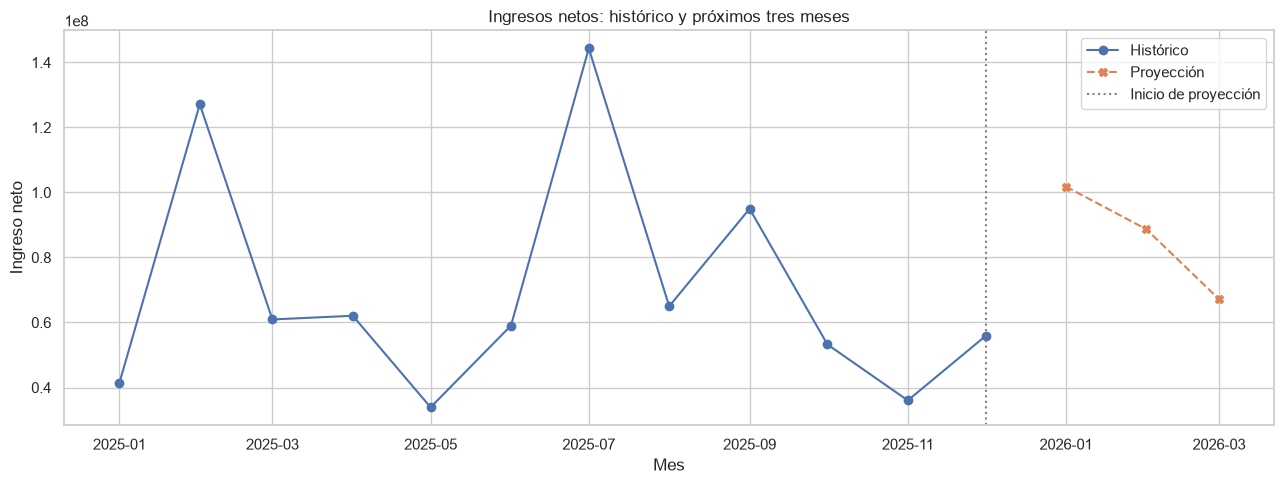

Modelo con menor MAE: Regresión lineal
Ingreso proyectado acumulado: $257,609,220
Variación de la última proyección frente al último mes: 20.3%


In [8]:
history = series[['mes', 'ingreso_neto']].copy()
forecast_rows = []
for step in range(3):
    next_month = history['mes'].max() + pd.offsets.MonthBegin(1)
    next_features = pd.DataFrame([{'tendencia': len(series) + step, 'ingreso_lag_1': history['ingreso_neto'].iloc[-1], 'media_movil_3': history['ingreso_neto'].tail(3).mean()}])
    value = float(regression.predict(next_features[features])[0])
    forecast_rows.append({'mes': next_month, 'ingreso_proyectado': value})
    history = pd.concat([history, pd.DataFrame([{'mes': next_month, 'ingreso_neto': value}])], ignore_index=True)
forecast = pd.DataFrame(forecast_rows)
display(forecast.assign(ingreso_proyectado=forecast['ingreso_proyectado'].map(lambda value: f'${value:,.0f}')))
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(series['mes'], series['ingreso_neto'], marker='o', label='Histórico')
ax.plot(forecast['mes'], forecast['ingreso_proyectado'], marker='X', linestyle='--', label='Proyección')
ax.axvline(series['mes'].max(), color='gray', linestyle=':', label='Inicio de proyección')
ax.set(title='Ingresos netos: histórico y próximos tres meses', xlabel='Mes', ylabel='Ingreso neto'); ax.legend(); plt.tight_layout(); plt.show()
print('Modelo con menor MAE:', scores['MAE'].idxmin())
print(f'Ingreso proyectado acumulado: ${forecast.ingreso_proyectado.sum():,.0f}')
print(f'Variación de la última proyección frente al último mes: {(forecast.ingreso_proyectado.iloc[-1] / series.ingreso_neto.iloc[-1] - 1) * 100:,.1f}%')

### Interpretación y recomendaciones

- Si la regresión obtiene menor MAE/RMSE que el baseline, aporta una señal adicional frente a usar solo el último mes; si no, se debe conservar el baseline y recolectar más historia o variables explicativas.
- Una proyección creciente puede apoyar compras y disponibilidad; una decreciente puede activar revisión de precios, canales, productos y retención.
- Las devoluciones deben monitorearse como indicador de calidad o satisfacción, no eliminarse sin justificación.
- Para una siguiente versión se recomienda incorporar estacionalidad, promociones, margen, inventario, días festivos y validación con varios cortes temporales.

## Conclusiones

1. El análisis descriptivo permitió observar la evolución mensual de los ingresos y la contribución acumulada de los canales; el análisis predictivo transforma ese histórico en un escenario de ingresos futuros.
2. La limpieza fue necesaria para hacer comparable la información: se unificaron fechas y categorías, se transformaron descuentos y se conservaron las devoluciones porque afectan el ingreso neto.
3. La regresión lineal se evaluó con una división temporal y se comparó con una regla ingenua. El modelo que presente menor MAE/RMSE en la tabla de resultados será la alternativa preferida para esta línea base, sin interpretar la métrica como garantía.
4. La proyección de tres meses puede apoyar decisiones de inventario, presupuesto y campañas, pero debe revisarse junto con promociones, capacidad, competencia y nueva información.
5. La principal limitación es la cantidad y el alcance temporal de los datos. Para una versión productiva se deben agregar estacionalidad, margen, inventario, campañas, festivos y validación en varios periodos.

En conclusión, el notebook cumple el ciclo de análisis predictivo: comprende el problema empresarial, prepara los datos, selecciona variables, entrena y valida un modelo, visualiza resultados y los traduce en decisiones futuras con sus límites explícitos.

## Referencias

1. Google Cloud. (s. f.). *¿Qué es el análisis predictivo?* [Artículo en español](https://cloud.google.com/learn/what-is-predictive-analytics?hl=es). Consulta: 27 de octubre de 2026.
2. *Guía Analítica Empresarial*. Capítulo: Análisis predictivo. Material suministrado para la actividad: `Práctica de Analítica Predictiva Empresarial.pdf`.
3. Scikit-learn. (s. f.). *LinearRegression*. [Documentación oficial](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).